## 1. Imports and reproducibility

In [1]:
import time
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Load and inspect the dataset

In [2]:
data = fetch_openml(data_id=1597, as_frame=True)
df = data.frame.copy()

display(df.head())
print("Dataset shape:", df.shape)
print(df.info())
display(df.describe().T)
print("\\nClass distribution:")
print(df["Class"].value_counts())
print("\\nClass percentages:")
print((df["Class"].value_counts(normalize=True) * 100).round(4))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Dataset shape: (284807, 30)
<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 30 columns):
 #   Column  Non-Null Count   Dtype   
---  ------  --------------   -----   
 0   V1      284807 non-null  float64 
 1   V2      284807 non-null  float64 
 2   V3      284807 non-null  float64 
 3   V4      284807 non-null  float64 
 4   V5      284807 non-null  float64 
 5   V6      284807 non-null  float64 
 6   V7      284807 non-null  float64 
 7   V8      284807 non-null  float64 
 8   V9      284807 non-null  float64 
 9   V10     284807 non-null  float64 
 10  V11     284807 non-null  float64 
 11  V12     284807 non-null  float64 
 12  V13     284807 non-null  float64 
 13  V14     284807 non-null  float64 
 14  V15     284807 non-null  float64 
 15  V16     284807 non-null  float64 
 16  V17     284807 non-null  float64 
 17  V18     284807 non-null  float64 
 18  V19     284807 non-null  float64 
 19  V20     284807 non-null  float64 
 20  V21     2

,count,mean,std,min,25%,50%,75%,max
V1,284807.0,1.175161e-15,1.958696,-56.407510,-0.920373,0.018109,1.315642,2.454930
V2,284807.0,3.384974e-16,1.651309,-72.715728,-0.598550,0.065486,0.803724,22.057729
V3,284807.0,-1.379537e-15,1.516255,-48.325589,-0.890365,0.179846,1.027196,9.382558
V4,284807.0,2.094852e-15,1.415869,-5.683171,-0.848640,-0.019847,0.743341,16.875344
V5,284807.0,1.021879e-15,1.380247,-113.743307,-0.691597,-0.054336,0.611926,34.801666
V6,284807.0,1.494498e-15,1.332271,-26.160506,-0.768296,-0.274187,0.398565,73.301626
V7,284807.0,-5.620335e-16,1.237094,-43.557242,-0.554076,0.040103,0.570436,120.589494
V8,284807.0,1.149614e-16,1.194353,-73.216718,-0.208630,0.022358,0.327346,20.007208
V9,284807.0,-2.414189e-15,1.098632,-13.434066,-0.643098,-0.051429,0.597139,15.594995
V10,284807.0,2.236957e-15,1.088850,-24.588262,-0.535426,-0.092917,0.453923,23.745136


\nClass distribution:
Class
0    284315
1       492
Name: count, dtype: int64
\nClass percentages:
Class
0    99.8273
1     0.1727
Name: proportion, dtype: float64


## 3. Duplicate analysis and removal


In [3]:
df["Class"] = df["Class"].astype(int)

print("Exact duplicate rows:", df.duplicated().sum())

duplicate_rows = df[df.duplicated(keep=False)]
print("\\nDuplicated rows by class:")
print(duplicate_rows["Class"].value_counts())

print("\\nClass distribution among duplicated rows (%):")
print((duplicate_rows["Class"].value_counts(normalize=True) * 100).round(4))

df = df.drop_duplicates().reset_index(drop=True)

print("\\nShape after duplicate removal:", df.shape)
print("Remaining duplicates:", df.duplicated().sum())
print("\\nClass distribution after duplicate removal:")
print(df["Class"].value_counts())

Exact duplicate rows: 9144
\nDuplicated rows by class:
Class
0    14261
1       32
Name: count, dtype: int64
\nClass distribution among duplicated rows (%):
Class
0    99.7761
1     0.2239
Name: proportion, dtype: float64
\nShape after duplicate removal: (275663, 30)
Remaining duplicates: 0
\nClass distribution after duplicate removal:
Class
0    275190
1       473
Name: count, dtype: int64


## 4. Separate features and target

In [4]:
X = df.drop(columns=["Class"])
y = df["Class"]

print("X shape:", X.shape)
print("y shape:", y.shape)
print("Feature columns:", X.columns.tolist())

X shape: (275663, 29)
y shape: (275663,)
Feature columns: ['V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount']


## 5. Train, validation, and test split
Overall proportions: **64% fit / 16% validation / 20% test**.

In [5]:
X_train_all, X_test, y_train_all, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

X_fit, X_val, y_fit, y_val = train_test_split(
    X_train_all,
    y_train_all,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_train_all
)

print("Fit:", X_fit.shape, y_fit.value_counts().to_dict())
print("Validation:", X_val.shape, y_val.value_counts().to_dict())
print("Test:", X_test.shape, y_test.value_counts().to_dict())

Fit: (176424, 29) {0: 176122, 1: 302}
Validation: (44106, 29) {0: 44030, 1: 76}
Test: (55133, 29) {0: 55038, 1: 95}


## 6. XGBoost


In [7]:
xgb_model = XGBClassifier(
    device="cuda",
    tree_method="hist",
    random_state=RANDOM_STATE,
    eval_metric="aucpr"
)

xgb_param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 7],
    "learning_rate": [0.03, 0.05, 0.1]
}

xgb_grid = GridSearchCV(
    estimator=xgb_model,
    param_grid=xgb_param_grid,
    scoring="average_precision",
    cv=3,
    n_jobs=1,
    verbose=2
)

xgb_grid.fit(X_fit, y_fit)

best_xgb = xgb_grid.best_estimator_
print("Best XGBoost parameters:", xgb_grid.best_params_)
print("Best XGBoost CV AP:", xgb_grid.best_score_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=100; total time=   0.6s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=100; total time=   0.3s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=100; total time=   0.3s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=200; total time=   0.4s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=200; total time=   0.4s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=200; total time=   0.4s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=300; total time=   0.5s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=300; total time=   0.5s
[CV] END ..learning_rate=0.03, max_depth=3, n_estimators=300; total time=   0.5s
[CV] END ..learning_rate=0.03, max_depth=5, n_estimators=100; total time=   0.3s
[CV] END ..learning_rate=0.03, max_depth=5, n_estimators=100; total time=   0.3s
[CV] END ..learning_rate=0.03, max_depth=5, n_es

## 7. Random Forest



In [8]:
rf = RandomForestClassifier(
    random_state=RANDOM_STATE,
    class_weight="balanced",
    n_jobs=1
)

rf_param_dist = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6, 8, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": ["sqrt", "log2"]
}

rf_search = RandomizedSearchCV(
    estimator=rf,
    param_distributions=rf_param_dist,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    n_jobs=-1,
    random_state=RANDOM_STATE,
    verbose=2
)

rf_search.fit(X_fit, y_fit)

best_rf = rf_search.best_estimator_
print("Best Random Forest parameters:", rf_search.best_params_)
print("Best Random Forest CV AP:", rf_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best Random Forest parameters: {'n_estimators': 200, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 10}
Best Random Forest CV AP: 0.823772451707515


## 8. LightGBM



In [9]:
lgb_model = LGBMClassifier(
    objective="binary",
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbosity=-1
)

lgb_param_dist = {
    "n_estimators": [100, 200, 300, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "num_leaves": [15, 31, 50, 63],
    "max_depth": [-1, 5, 8, 10],
    "min_child_samples": [10, 20, 30, 50],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.8, 0.9, 1.0],
    "reg_lambda": [0, 0.1, 1, 5]
}

lgb_search = RandomizedSearchCV(
    estimator=lgb_model,
    param_distributions=lgb_param_dist,
    n_iter=20,
    scoring="average_precision",
    cv=3,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=2
)

lgb_search.fit(X_fit, y_fit)

best_lgb = lgb_search.best_estimator_
print("Best LightGBM parameters:", lgb_search.best_params_)
print("Best LightGBM CV AP:", lgb_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=-1, min_child_samples=30, n_estimators=200, num_leaves=15, reg_lambda=0.1, subsample=0.8; total time=   3.5s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=-1, min_child_samples=30, n_estimators=200, num_leaves=15, reg_lambda=0.1, subsample=0.8; total time=   3.3s
[CV] END colsample_bytree=0.9, learning_rate=0.03, max_depth=-1, min_child_samples=30, n_estimators=200, num_leaves=15, reg_lambda=0.1, subsample=0.8; total time=   3.0s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=5, min_child_samples=10, n_estimators=200, num_leaves=63, reg_lambda=1, subsample=1.0; total time=   2.7s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=5, min_child_samples=10, n_estimators=200, num_leaves=63, reg_lambda=1, subsample=1.0; total time=   2.8s
[CV] END colsample_bytree=0.8, learning_rate=0.01, max_depth=5, min_child_samples=10, n_estimat

## 9. CatBoost



In [10]:
cat_model = CatBoostClassifier(
    loss_function="Logloss",
    eval_metric="PRAUC",
    auto_class_weights="Balanced",
    random_seed=RANDOM_STATE,
    verbose=0,
    thread_count=1,
    allow_writing_files=False
)

cat_param_dist = {
    "iterations": [300, 500, 700],
    "learning_rate": [0.03, 0.05, 0.1],
    "depth": [4, 6, 8],
    "l2_leaf_reg": [3, 5, 7]
}

cat_search = RandomizedSearchCV(
    estimator=cat_model,
    param_distributions=cat_param_dist,
    n_iter=10,
    scoring="average_precision",
    cv=3,
    n_jobs=1,
    random_state=RANDOM_STATE,
    verbose=2
)

cat_search.fit(X_fit, y_fit)

best_cat = cat_search.best_estimator_
print("Best CatBoost parameters:", cat_search.best_params_)
print("Best CatBoost CV AP:", cat_search.best_score_)

Fitting 3 folds for each of 10 candidates, totalling 30 fits
[CV] END depth=6, iterations=300, l2_leaf_reg=5, learning_rate=0.03; total time=  20.6s
[CV] END depth=6, iterations=300, l2_leaf_reg=5, learning_rate=0.03; total time=  19.1s
[CV] END depth=6, iterations=300, l2_leaf_reg=5, learning_rate=0.03; total time=  18.9s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time=  14.2s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time=  14.1s
[CV] END depth=4, iterations=300, l2_leaf_reg=3, learning_rate=0.03; total time=  13.9s
[CV] END depth=4, iterations=700, l2_leaf_reg=5, learning_rate=0.05; total time=  30.2s
[CV] END depth=4, iterations=700, l2_leaf_reg=5, learning_rate=0.05; total time=  29.8s
[CV] END depth=4, iterations=700, l2_leaf_reg=5, learning_rate=0.05; total time=  29.2s
[CV] END depth=6, iterations=300, l2_leaf_reg=5, learning_rate=0.05; total time=  18.6s
[CV] END depth=6, iterations=300, l2_leaf_reg=5, learning_r

## 10. Validation probabilities and threshold selection



In [11]:
models = {
    "XGBoost": best_xgb,
    "Random Forest": best_rf,
    "LightGBM": best_lgb,
    "CatBoost": best_cat
}

validation_probabilities = {}

for name, model in models.items():
    validation_probabilities[name] = model.predict_proba(X_val)[:, 1]

threshold_candidates = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]

threshold_rows = []

for name, y_proba in validation_probabilities.items():
    for threshold in threshold_candidates:
        y_pred_threshold = (y_proba >= threshold).astype(int)

        threshold_rows.append({
            "Model": name,
            "Threshold": threshold,
            "Precision": precision_score(y_val, y_pred_threshold, zero_division=0),
            "Recall": recall_score(y_val, y_pred_threshold, zero_division=0),
            "F1": f1_score(y_val, y_pred_threshold, zero_division=0)
        })

threshold_results = pd.DataFrame(threshold_rows)
display(threshold_results.round(4))

best_threshold_rows = threshold_results.loc[
    threshold_results.groupby("Model")["F1"].idxmax()
].reset_index(drop=True)

print("Best validation threshold for each model:")
display(best_threshold_rows.round(4))

selected_thresholds = dict(
    zip(best_threshold_rows["Model"], best_threshold_rows["Threshold"])
)

,Model,Threshold,Precision,Recall,F1
0,XGBoost,0.1,0.8824,0.7895,0.8333
1,XGBoost,0.2,0.9091,0.7895,0.8451
2,XGBoost,0.3,0.9365,0.7763,0.8489
3,XGBoost,0.4,0.9516,0.7763,0.8551
4,XGBoost,0.5,0.9516,0.7763,0.8551
5,XGBoost,0.6,0.9492,0.7368,0.8296
6,XGBoost,0.7,0.9483,0.7237,0.8209
7,XGBoost,0.8,0.9483,0.7237,0.8209
8,XGBoost,0.9,0.9474,0.7105,0.8120
9,Random Forest,0.1,0.0675,0.8553,0.1251


Best validation threshold for each model:


,Model,Threshold,Precision,Recall,F1
0,CatBoost,0.9,0.8429,0.7763,0.8082
1,LightGBM,0.6,0.9375,0.7895,0.8571
2,Random Forest,0.7,0.8382,0.7500,0.7917
3,XGBoost,0.4,0.9516,0.7763,0.8551


## 11. Precision–Recall curve comparison

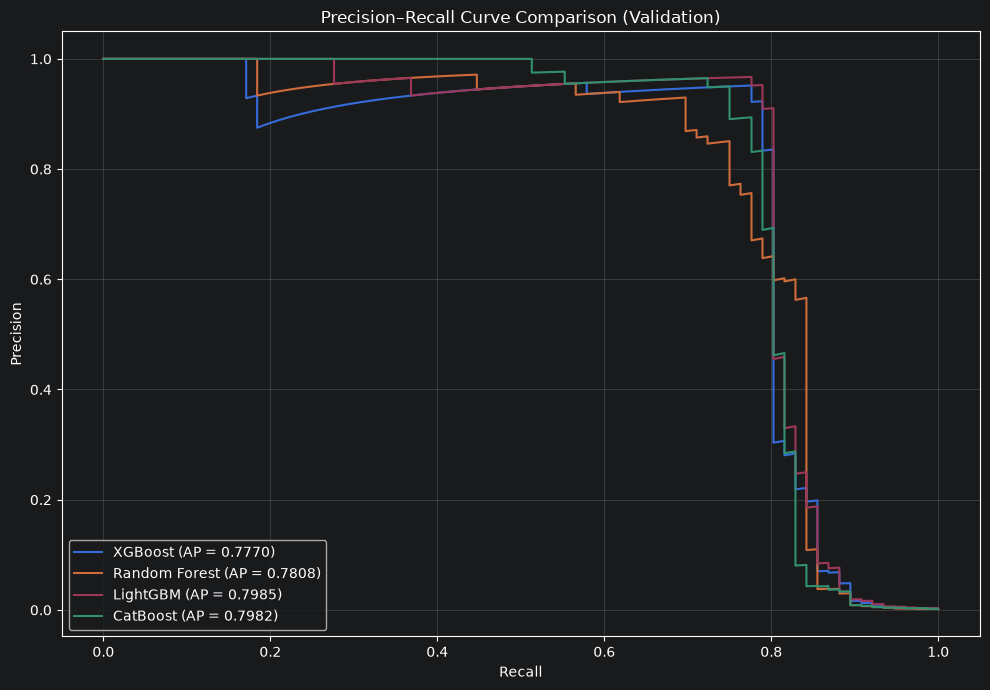

In [12]:
plt.figure(figsize=(10, 7))

for name, y_proba in validation_probabilities.items():
    precision, recall, _ = precision_recall_curve(y_val, y_proba)
    ap = average_precision_score(y_val, y_proba)

    plt.plot(recall, precision, label=f"{name} (AP = {ap:.4f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curve Comparison (Validation)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 12. Validation model comparison


In [13]:
comparison_rows = []

for name, model in models.items():
    y_proba = validation_probabilities[name]
    threshold = selected_thresholds[name]
    y_pred = (y_proba >= threshold).astype(int)

    comparison_rows.append({
        "Model": name,
        "Threshold": threshold,
        "Average Precision": average_precision_score(y_val, y_proba),
        "Precision": precision_score(y_val, y_pred, zero_division=0),
        "Recall": recall_score(y_val, y_pred, zero_division=0),
        "F1-score": f1_score(y_val, y_pred, zero_division=0)
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values(
    by="Average Precision",
    ascending=False
).reset_index(drop=True)

display(comparison_df.round(4))

,Model,Threshold,Average Precision,Precision,Recall,F1-score
0,LightGBM,0.6,0.7985,0.9375,0.7895,0.8571
1,CatBoost,0.9,0.7982,0.8429,0.7763,0.8082
2,Random Forest,0.7,0.7808,0.8382,0.7500,0.7917
3,XGBoost,0.4,0.7770,0.9516,0.7763,0.8551


## 13. Final model



In [14]:
final_threshold = selected_thresholds["LightGBM"]
final_lgb = LGBMClassifier(
    objective="binary",
    **lgb_search.best_params_,
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
    verbosity=-1
)

final_lgb.fit(X_train_all, y_train_all)

print("Final LightGBM parameters:")
print(final_lgb.get_params())
print("Selected validation threshold:", final_threshold)

Final LightGBM parameters:
{'boosting_type': 'gbdt', 'class_weight': 'balanced', 'colsample_bytree': 0.8, 'importance_type': 'split', 'learning_rate': 0.1, 'max_depth': 8, 'min_child_samples': 30, 'min_child_weight': 0.001, 'min_split_gain': 0.0, 'n_estimators': 500, 'n_jobs': -1, 'num_leaves': 15, 'objective': 'binary', 'random_state': 42, 'reg_alpha': 0.0, 'reg_lambda': 0.1, 'subsample': 0.9, 'subsample_for_bin': 200000, 'subsample_freq': 0, 'verbosity': -1}
Selected validation threshold: 0.6


## 14. Final test evaluation



Final threshold: 0.6
\nClassification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     55038
           1       0.88      0.79      0.83        95

    accuracy                           1.00     55133
   macro avg       0.94      0.89      0.92     55133
weighted avg       1.00      1.00      1.00     55133

Confusion Matrix:
[[55028    10]
 [   20    75]]


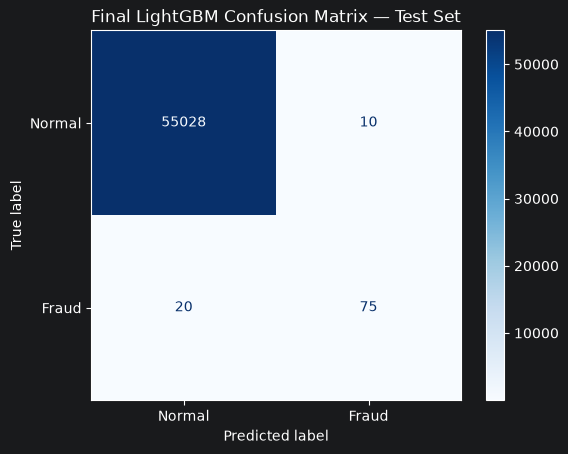

Test Average Precision: 0.8482561417205045


In [15]:
y_proba_test = final_lgb.predict_proba(X_test)[:, 1]
y_pred_test = (y_proba_test >= final_threshold).astype(int)

print("Final threshold:", final_threshold)
print("\\nClassification Report:")
print(classification_report(y_test, y_pred_test, zero_division=0))

print("Confusion Matrix:")
cm = confusion_matrix(y_test, y_pred_test)
print(cm)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Fraud"]
)
disp.plot(cmap="Blues")
plt.title("Final LightGBM Confusion Matrix — Test Set")
plt.show()

test_ap = average_precision_score(y_test, y_proba_test)
print("Test Average Precision:", test_ap)

## 15. Save the final model and threshold

In [16]:
joblib.dump(final_lgb, "final_lightgbm_model.pkl")
joblib.dump(final_threshold, "classification_threshold.pkl")

print("Model and threshold saved successfully.")

Model and threshold saved successfully.
